# DQN and PPO Portfolio Analysis

This notebook trains or loads the reinforcement-learning agents, charts their individual results, then imports the saved LSTM returns and performs the final model comparison.

## 1. Setup

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.agents.train_agents import train_dqn, train_ppo
from src.data.splits import chronological_split
from src.evaluation.evaluate import compare_strategies, save_evaluation
from src.portfolio.metrics import performance_summary
from src.utils.config import DEFAULT_CONFIG

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
report_directory = PROJECT_ROOT / "results/reports"
model_directory = PROJECT_ROOT / "results/models"
print(f"Project root: {PROJECT_ROOT}")


Project root: d:\Codings\DRL\Portfolio_DRL


## 2. Load returns once and recreate the fixed chronological split

In [2]:
returns = pd.read_csv(
    PROJECT_ROOT / DEFAULT_CONFIG.returns_path,
    index_col=0,
    parse_dates=True,
).dropna().sort_index()
train_returns, validation_returns, test_returns = chronological_split(
    returns,
    DEFAULT_CONFIG.train_end,
    DEFAULT_CONFIG.validation_end,
)
print({"train": len(train_returns), "validation": len(validation_returns), "test": len(test_returns)})

{'train': 1258, 'validation': 250, 'test': 502}


## 3. Train or reuse PPO and DQN

Set `TRAIN_AGENTS = True` for the first run. Training can take considerable time. After the model files exist, change it to `False` to regenerate charts without retraining.

In [3]:
TRAIN_AGENTS = True

ppo_path = model_directory / "ppo_portfolio.zip"
dqn_path = model_directory / "dqn_portfolio.zip"

if TRAIN_AGENTS or not ppo_path.exists():
    print("Training PPO...")
    train_ppo(train_returns, validation_returns, DEFAULT_CONFIG)
else:
    print("Using saved PPO model.")

if TRAIN_AGENTS or not dqn_path.exists():
    print("Training DQN...")
    train_dqn(train_returns, validation_returns, DEFAULT_CONFIG)
else:
    print("Using saved DQN model.")

Training PPO...
Using cpu device
Logging to results\reports\tensorboard\ppo_seed_42_1
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 1.23e+03 |
|    ep_rew_mean     | -599     |
| time/              |          |
|    fps             | 2099     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 1.23e+03    |
|    ep_rew_mean          | -483        |
| time/                   |             |
|    fps                  | 1961        |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.005450432 |
|    clip_fraction        | 0.0147      |
|    clip_range           | 0.2         |
|    entropy_loss         | 

## 4. Evaluate DQN and PPO against classical baselines

In [4]:
drl_returns, drl_metrics = compare_strategies(train_returns, test_returns, DEFAULT_CONFIG)
saved_paths = save_evaluation(drl_returns, drl_metrics, DEFAULT_CONFIG)
display(drl_metrics.style.format("{:.4f}"))
saved_paths

d:\Codings\DRL\Portfolio_DRL\venv\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


,total_return,annualised_return,annualised_volatility,sharpe_ratio,sortino_ratio,maximum_drawdown
PPO,0.4136,0.2030,0.2747,0.8090,0.8341,0.3010
DQN,0.3307,0.1648,0.2832,0.6785,0.7487,0.2028
Equal Weight,0.5479,0.2627,0.2307,1.1260,1.1475,0.2529
Markowitz,0.3599,0.1784,0.2106,0.8838,0.8814,0.2563


{'returns': WindowsPath('results/reports/out_of_sample_returns.csv'),
 'metrics': WindowsPath('results/reports/performance_metrics.csv'),
 'figure': WindowsPath('results/figures/strategy_comparison.png')}

## 5. PPO results

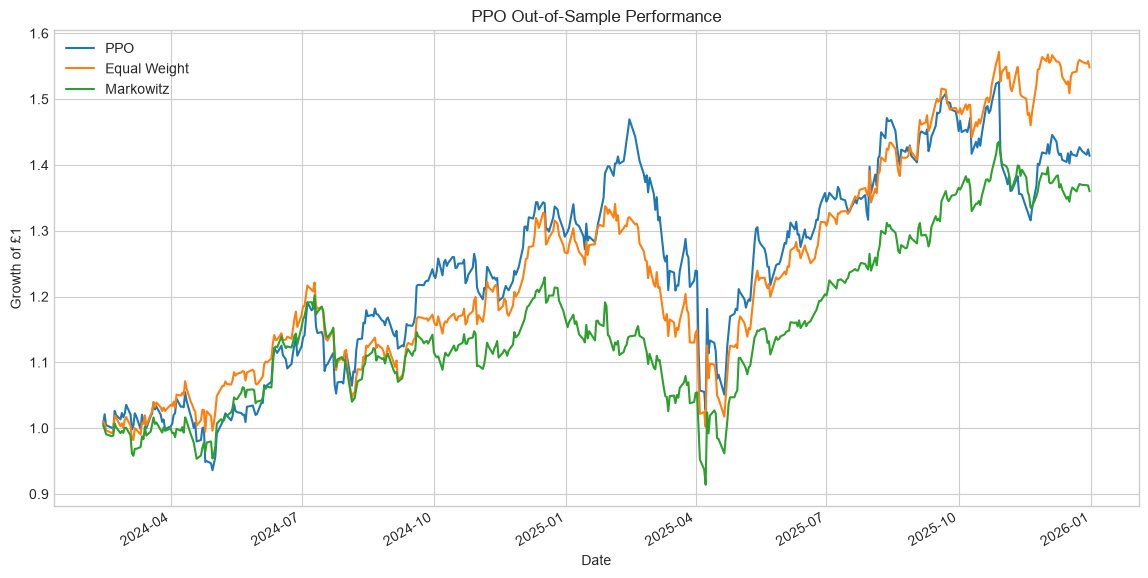

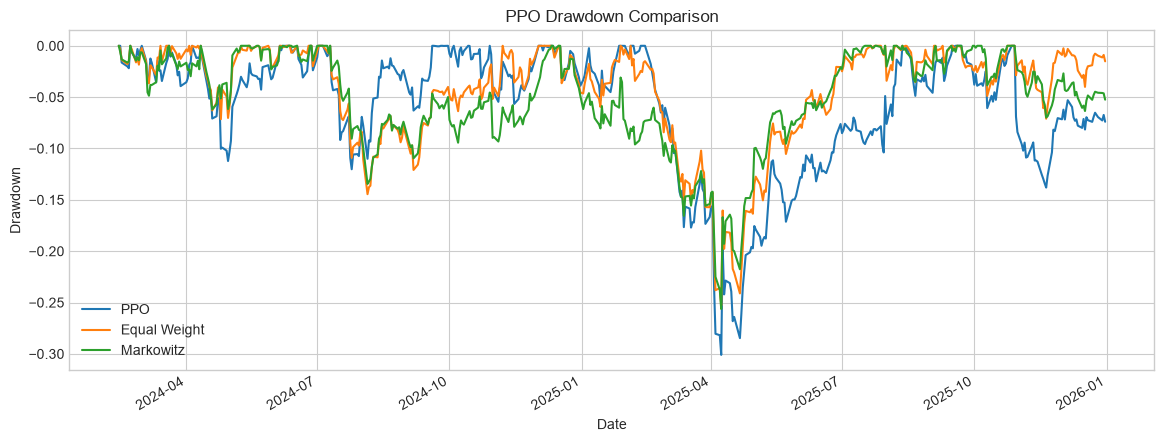

,total_return,annualised_return,annualised_volatility,sharpe_ratio,sortino_ratio,maximum_drawdown
PPO,0.4136,0.2030,0.2747,0.8090,0.8341,0.3010
Equal Weight,0.5479,0.2627,0.2307,1.1260,1.1475,0.2529
Markowitz,0.3599,0.1784,0.2106,0.8838,0.8814,0.2563


In [5]:
ppo_comparison = drl_returns[["PPO", "Equal Weight", "Markowitz"]]
(1 + ppo_comparison).cumprod().plot(figsize=(14, 7), title="PPO Out-of-Sample Performance")
plt.ylabel("Growth of £1")
plt.show()

ppo_wealth = (1 + ppo_comparison).cumprod()
ppo_drawdown = ppo_wealth.div(ppo_wealth.cummax()).sub(1)
ppo_drawdown.plot(figsize=(14, 5), title="PPO Drawdown Comparison")
plt.ylabel("Drawdown")
plt.show()

display(drl_metrics.loc[["PPO", "Equal Weight", "Markowitz"]].style.format("{:.4f}"))

## 6. DQN results

Remember that vanilla DQN uses a restricted action set: equal weight or full allocation to one asset. This is not directly equivalent to PPO's continuous allocation space.

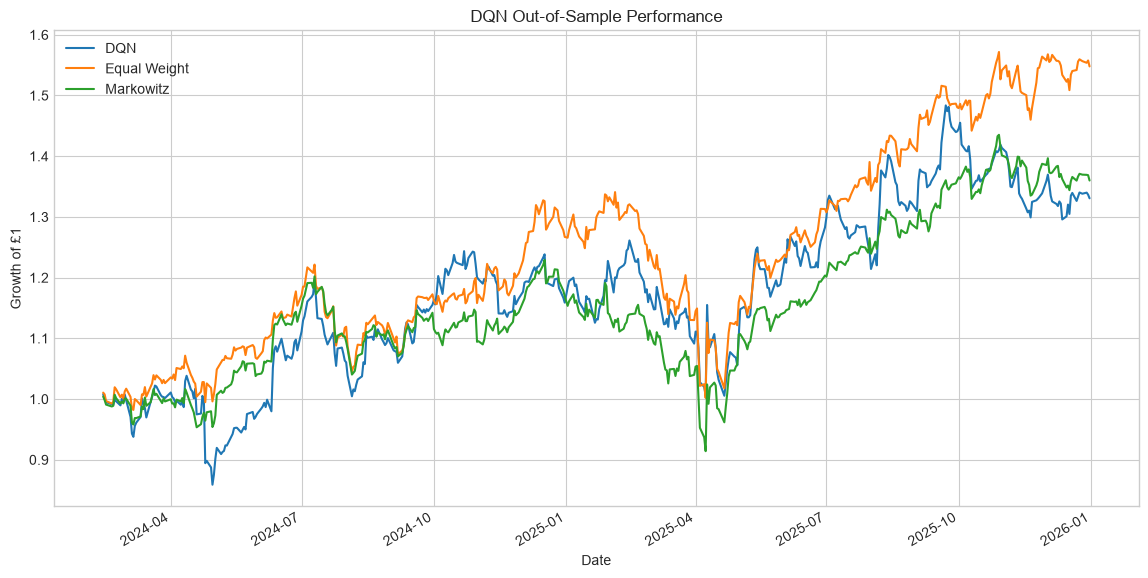

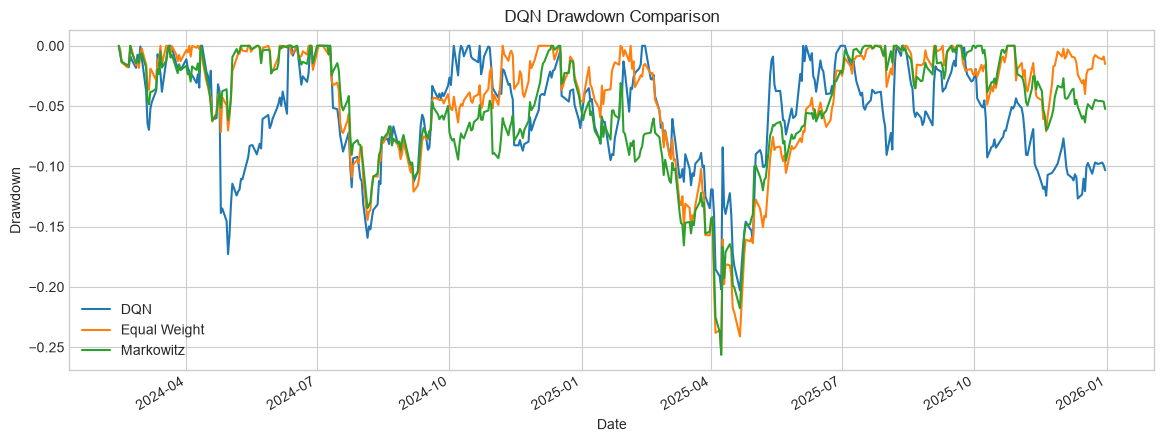

,total_return,annualised_return,annualised_volatility,sharpe_ratio,sortino_ratio,maximum_drawdown
DQN,0.3307,0.1648,0.2832,0.6785,0.7487,0.2028
Equal Weight,0.5479,0.2627,0.2307,1.1260,1.1475,0.2529
Markowitz,0.3599,0.1784,0.2106,0.8838,0.8814,0.2563


In [6]:
dqn_comparison = drl_returns[["DQN", "Equal Weight", "Markowitz"]]
(1 + dqn_comparison).cumprod().plot(figsize=(14, 7), title="DQN Out-of-Sample Performance")
plt.ylabel("Growth of £1")
plt.show()

dqn_wealth = (1 + dqn_comparison).cumprod()
dqn_drawdown = dqn_wealth.div(dqn_wealth.cummax()).sub(1)
dqn_drawdown.plot(figsize=(14, 5), title="DQN Drawdown Comparison")
plt.ylabel("Drawdown")
plt.show()

display(drl_metrics.loc[["DQN", "Equal Weight", "Markowitz"]].style.format("{:.4f}"))

## 7. Load the saved LSTM results

Run `01_lstm_analysis.ipynb` first. This notebook reads its saved return series; it does not retrain the LSTM or reload its raw inputs.

In [7]:
lstm_results_path = report_directory / "lstm_out_of_sample_returns.csv"
if not lstm_results_path.exists():
    raise FileNotFoundError("Run 01_lstm_analysis.ipynb completely before this comparison.")

lstm_results = pd.read_csv(lstm_results_path, index_col=0, parse_dates=True)
lstm_results.head()

,LSTM,Equal Weight,Markowitz
2024-01-02,-0.0217,-0.0191,-0.0228
2024-01-03,-0.0035,-0.0036,-0.0029
2024-01-04,-0.0100,-0.0113,-0.0098
2024-01-05,0.0013,0.0018,-0.0020
2024-01-08,0.0217,0.0223,0.0210


## 8. Final LSTM, DQN, PPO, and baseline comparison

,total_return,annualised_return,annualised_volatility,sharpe_ratio,sortino_ratio,maximum_drawdown
Equal Weight,0.5479,0.2627,0.2307,1.1260,1.1475,0.2529
LSTM,0.4904,0.2374,0.2263,1.0540,1.0489,0.2388
Markowitz,0.3599,0.1784,0.2106,0.8838,0.8814,0.2563
PPO,0.4136,0.2030,0.2747,0.8090,0.8341,0.3010
DQN,0.3307,0.1648,0.2832,0.6785,0.7487,0.2028


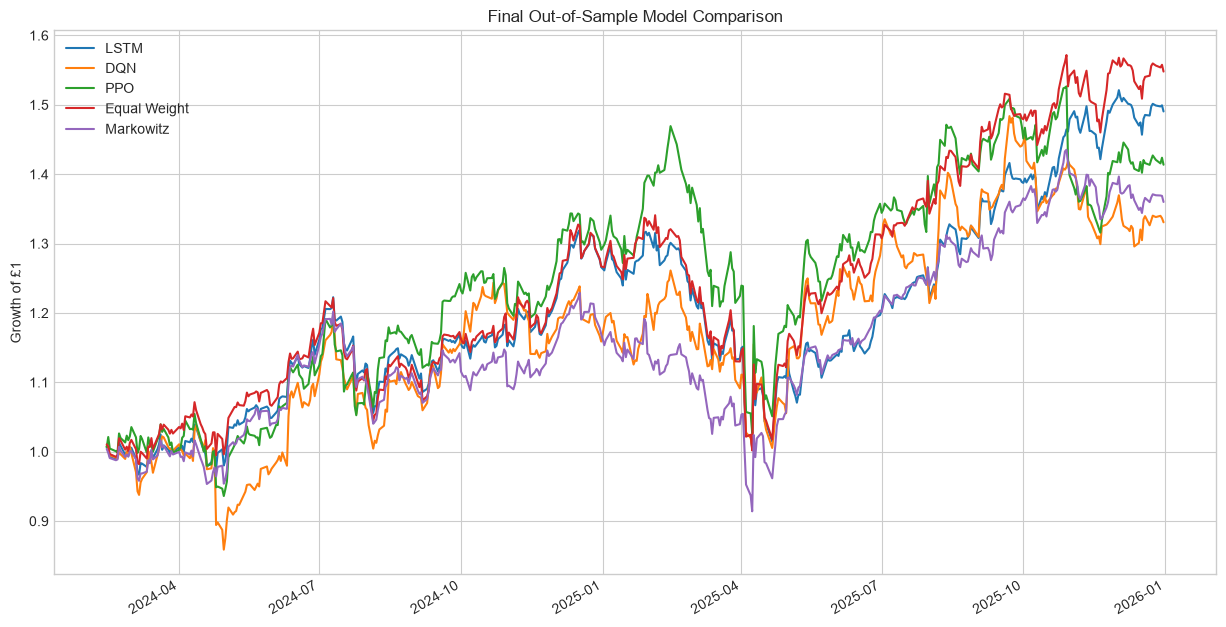

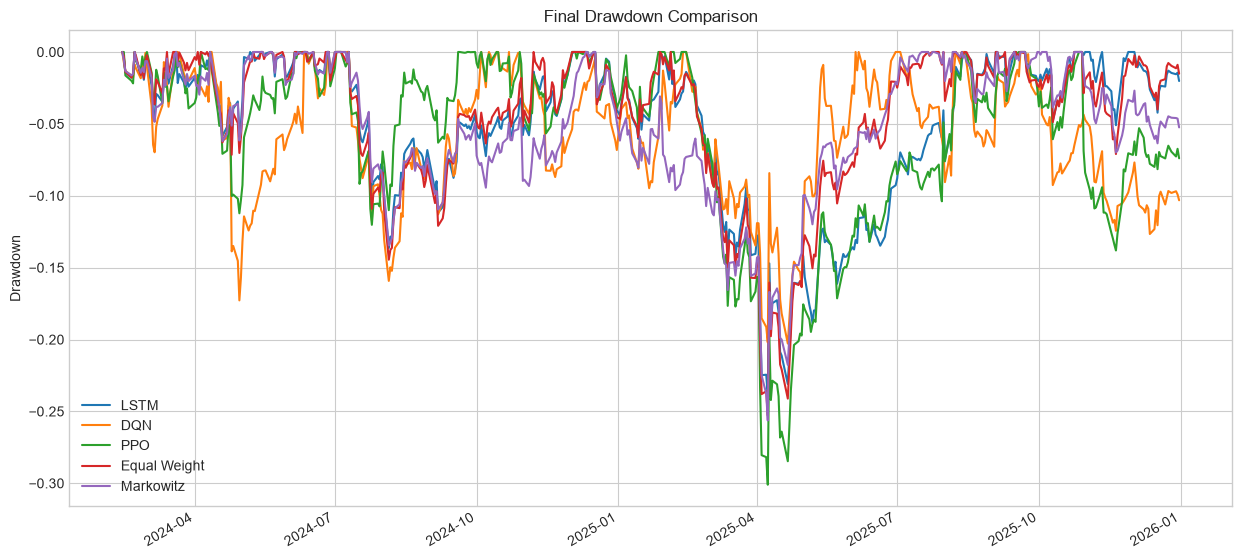

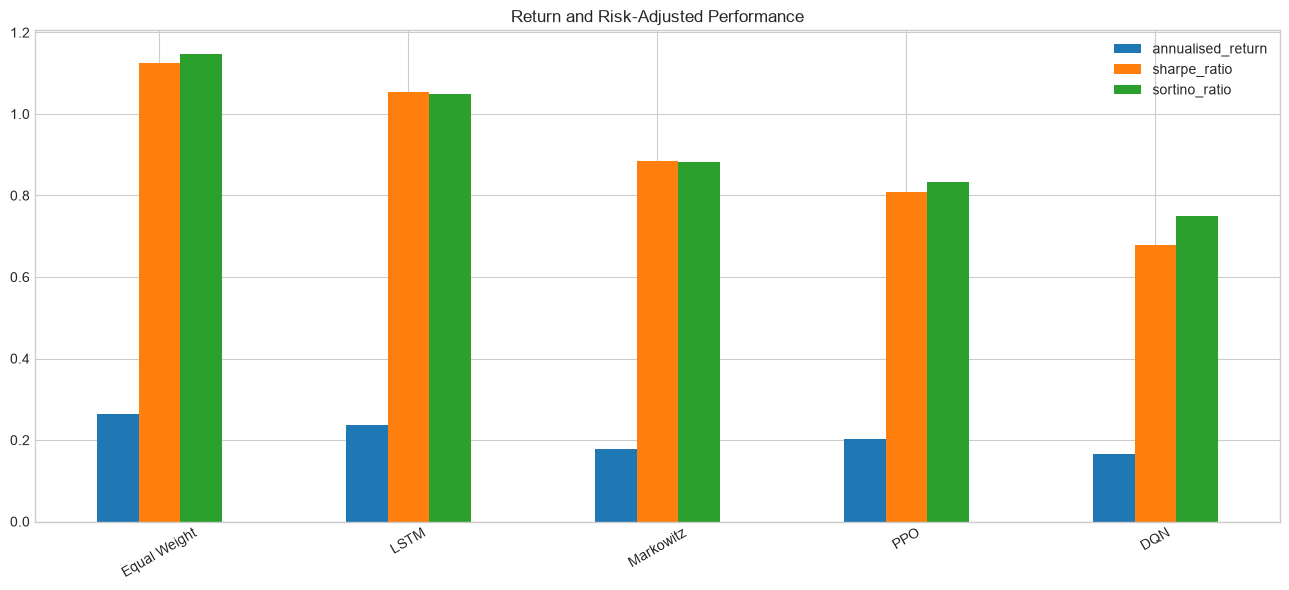

In [8]:
final_returns = pd.concat(
    [
        lstm_results[["LSTM"]],
        drl_returns[["DQN", "PPO", "Equal Weight", "Markowitz"]],
    ],
    axis=1,
).dropna()

final_metrics = pd.DataFrame(
    {name: performance_summary(series.to_numpy()) for name, series in final_returns.items()}
).T.sort_values("sharpe_ratio", ascending=False)
display(final_metrics.style.format("{:.4f}"))

(1 + final_returns).cumprod().plot(figsize=(15, 8), title="Final Out-of-Sample Model Comparison")
plt.ylabel("Growth of £1")
plt.show()

final_wealth = (1 + final_returns).cumprod()
final_drawdown = final_wealth.div(final_wealth.cummax()).sub(1)
final_drawdown.plot(figsize=(15, 7), title="Final Drawdown Comparison")
plt.ylabel("Drawdown")
plt.show()

final_metrics[["annualised_return", "sharpe_ratio", "sortino_ratio"]].plot.bar(
    figsize=(13, 6), title="Return and Risk-Adjusted Performance"
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 9. Save final metrics tables

In [9]:
final_returns.to_csv(report_directory / "final_model_returns.csv")
final_metrics.to_csv(report_directory / "final_model_comparison.csv")
print("Saved final return series and comparison table to results/reports.")

Saved final return series and comparison table to results/reports.
